#House Price prediction

In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv('/content/sample_data/california_housing_train.csv')
test_df = pd.read_csv('/content/sample_data/california_housing_test.csv')

In [3]:
df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [4]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df.columns)
print(df.duplicated().sum())

(17000, 9)
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
dtype: object
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value'],
      dtype='object')
0


In [5]:
df.describe()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [6]:
print(df['median_house_value'].describe())

count     17000.000000
mean     207300.912353
std      115983.764387
min       14999.000000
25%      119400.000000
50%      180400.000000
75%      265000.000000
max      500001.000000
Name: median_house_value, dtype: float64


#EDA

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

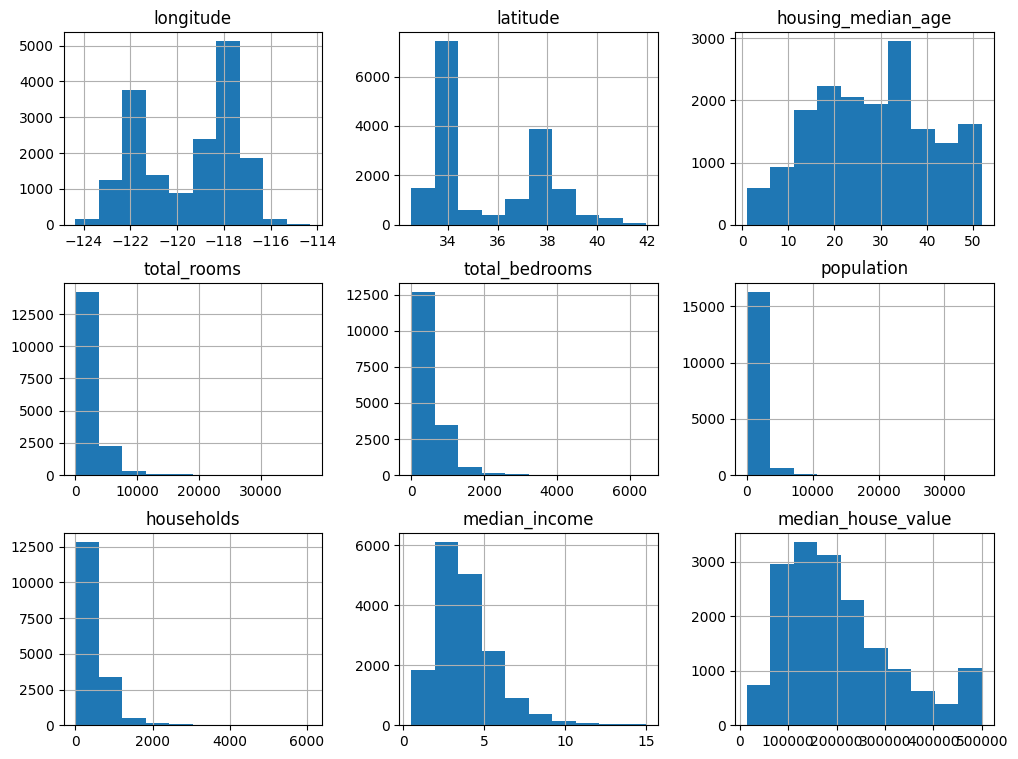

In [7]:
df.hist(figsize=(12,9))

<Axes: >

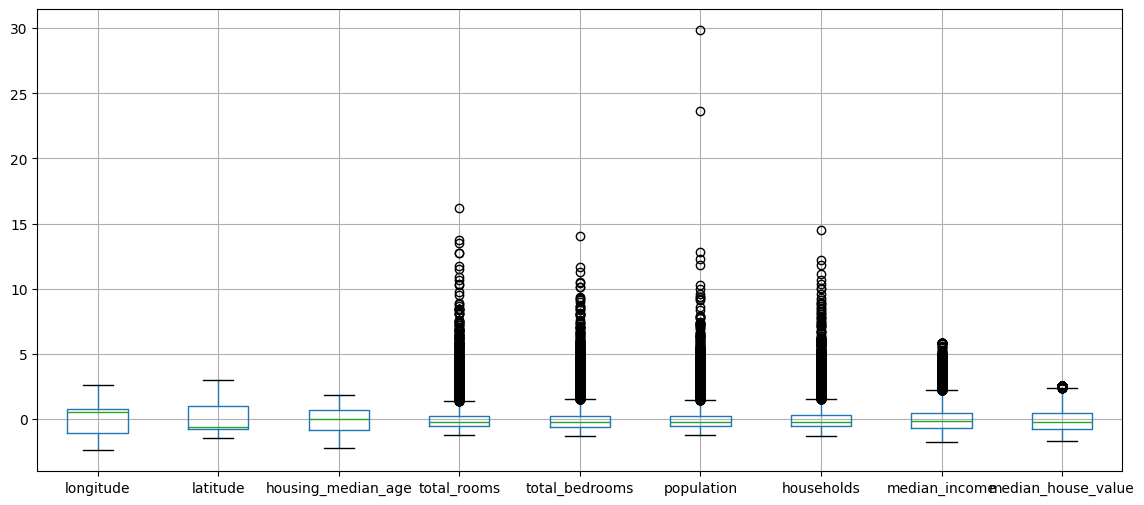

In [8]:
from sklearn.preprocessing import StandardScaler

scalar = StandardScaler()
scaled_data = scalar.fit_transform(df)
scaled_df =pd.DataFrame(scaled_data,columns = df.columns)
scaled_df.boxplot(figsize=(14, 6))

by this outliers are visibly seen total_rooms , total_bedrooms , population , households , median_income

In [9]:
df.corr(numeric_only=True)["median_house_value"].sort_values(
    ascending=False
)

,median_house_value
median_house_value,1.000000
median_income,0.691871
total_rooms,0.130991
housing_median_age,0.106758
households,0.061031
total_bedrooms,0.045783
population,-0.027850
longitude,-0.044982
latitude,-0.144917


By this we can see the most impact on house_value is by income

<Axes: xlabel='median_income', ylabel='median_house_value'>

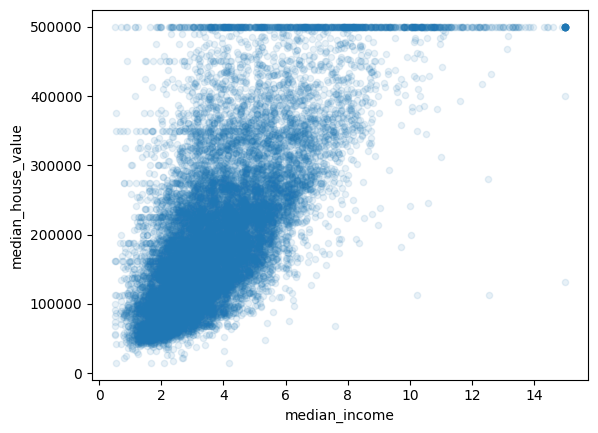

In [10]:
df.plot.scatter(
    x="median_income",
    y="median_house_value",
    alpha=0.1
)

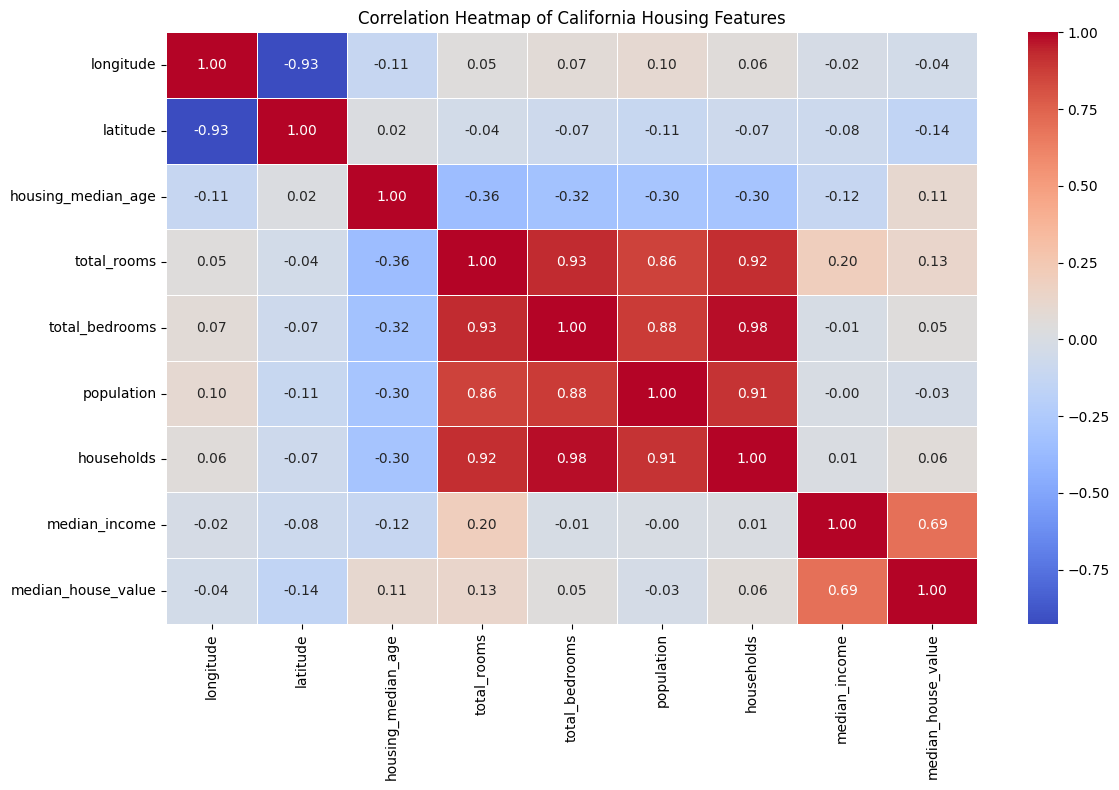

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of California Housing Features")
plt.tight_layout()
plt.show()


During EDA, I found that median_income has the strongest linear relationship with the target, with a correlation of approximately 0.67. I also found strong multicollinearity among total_rooms, total_bedrooms, population, and households. Additionally, latitude and longitude have a strong negative correlation, which is related to the geographical structure of the data

#Feature Engineering

In [12]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df['bedrooms_per_room'] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

test_df["rooms_per_household"] = test_df["total_rooms"] / test_df["households"]
test_df['bedrooms_per_room'] = test_df["total_bedrooms"] / test_df["total_rooms"]
test_df["population_per_household"] = test_df["population"] / test_df["households"]

In [13]:
df[[
    "rooms_per_household",
    'bedrooms_per_room',
    "population_per_household"
]].describe()

,rooms_per_household,bedrooms_per_room,population_per_household
count,17000.000000,17000.000000,17000.000000
mean,5.439044,0.212760,2.976337
std,2.539196,0.057823,4.037838
min,0.846154,0.100000,0.692308
25%,4.445275,0.175058,2.432609
50%,5.236106,0.202943,2.816872
75%,6.058097,0.239867,3.279435
max,141.909091,1.000000,502.461538


In [14]:
df.drop(columns= [ 'total_rooms' , 'total_bedrooms' , 'households' , "population"])
test_df.drop(columns= [ 'total_rooms' , 'total_bedrooms' , 'households' , "population"])

,longitude,latitude,housing_median_age,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.05,37.37,27.0,6.6085,344700.0,6.410891,0.170142,2.536304
1,-118.30,34.26,43.0,3.5990,176500.0,5.451264,0.205298,2.920578
2,-117.81,33.78,27.0,5.7934,270500.0,7.250505,0.141265,2.997980
3,-118.36,33.82,28.0,6.1359,330000.0,6.090909,0.223881,4.454545
4,-119.67,36.33,19.0,2.9375,81700.0,5.236287,0.196616,3.586498
...,...,...,...,...,...,...,...,...
2995,-119.86,34.42,23.0,1.1790,225000.0,2.388797,0.442759,2.072488
2996,-118.14,34.06,27.0,3.3906,237200.0,5.074324,0.205821,3.374517
2997,-119.70,36.30,10.0,2.2895,62000.0,4.345455,0.210251,3.150000
2998,-117.12,34.10,40.0,3.2708,162500.0,6.857143,0.145833,3.285714


#Train/Test Split

In [15]:
X_train = df.drop(columns=['median_house_value'])
y_train = df['median_house_value']

X_test = test_df.drop(columns=['median_house_value'])
y_test = test_df['median_house_value']

#Regression Model

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report,r2_score,mean_absolute_error,mean_squared_error
import numpy as np


rs = RandomForestRegressor(
    n_estimators = 100,
    max_depth = None,
    min_samples_leaf = 2,
    random_state= 42,
    n_jobs =-1
)

rs.fit(X_train,y_train)
y_pred = rs.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test,y_pred )))
print("R² Score:", r2_score(y_test, y_pred))

MAE: 32750.483829413715
RMSE: 51071.05328279849
R² Score: 0.7960996245906705


In [17]:
from xgboost import XGBRegressor
xg = XGBRegressor(
     n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1

)

xg.fit(X_train,y_train)
y_pred_xg = xg.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred_xg))
print("RMSE:", np.sqrt(mean_squared_error(y_test,y_pred_xg )))
print("R² Score:", r2_score(y_test, y_pred_xg))

MAE: 31139.747296875
RMSE: 48125.46573941417
R² Score: 0.8189417632050435


Final Result: The model achieved an MAE of 31,771.86 (average absolute prediction error of approximately $31.8K), an RMSE of 48,333.37 (penalizing larger prediction errors), and an R² score of 0.8174 (indicating that the model explains approximately 81.74% of the variation in house prices relative to a mean-prediction baseline), demonstrating promising performance in predicting California housing prices.
